# SupeRR Selector: Player Reliability Scores, Evidence-Based Rankings & Player Evaluation

In professional franchise cricket, recruitment decisions often suffer from two major flaws:
1. **Conflating volume with clutch execution:** Paying large sums for batters who score heavily in low-pressure dead rubbers or bowlers whose economy looks respectable only because they rarely bowl at the death.
2. **Conflating performance rating with evidence confidence:** An emerging player who struck at 200 across 20 clutch deliveries is performing well, but our statistical confidence in their sample is fundamentally different from a veteran who struck at 170 across 400 clutch deliveries.

In this notebook, I develop **Module 5: Player Reliability Scores & Evidence-Based Rankings**. 

### Core Analytical Foundations:
1. **Strict Decoupling of Performance vs Evidence:** We separate **Performance Rating** ($[0.0, 100.0]$, how well the player performed) from **Evidence Reliability** ($[0.0, 100.0]$, how much statistical confidence the sample supports across volume, matches, and tournaments).
2. **Independent Disciplines:** Batters and bowlers are evaluated through completely separate, cricket-justified frameworks.
3. **Traceable Multi-Dimensional Sub-scores:** Every player rating is mathematically traceable to specific tactical dimensions (pressure scoring rate, boundary conversion, strike rotation, wicket preservation, phase-adjusted run control, and true team dot creation).
4. **Transparent Eligibility Filtering:** Unstable small-sample records ($< 20$ clutch balls) are segregated into watchlists, preventing fluke noise from contaminating the main leaderboard.
5. **Rigorous Sensitivity & Robustness Auditing:** We stress-test the stability of our rankings across alternative weighting scenarios and threshold variations.


## 1. Setting Up the Pipeline and Importing Modular Libraries

All analytical logic is implemented in modular Python source files in `src/`:
* `src/reliability_scoring.py`: Computes the multi-factor Evidence Reliability Score ($ERS$) and discrete evidence tiers.
* `src/player_rating.py`: Computes transparent multi-dimensional batting and bowling performance ratings.
* `src/player_ranking.py`: Generates stratified leaderboards, role-wise rankings, and specialized analytical cohorts.
* `src/ranking_validation.py`: Stress-tests ranking stability across alternative weightings and threshold cutoffs.

Here, I initialize our environment and import these modules.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in path
root_path = os.path.abspath("..") if os.path.exists("../src") else os.path.abspath(".")
if root_path not in sys.path:
    sys.path.insert(0, root_path)

from src.reliability_scoring import calculate_batter_evidence_reliability, calculate_bowler_evidence_reliability
from src.player_rating import calculate_batting_performance_rating, calculate_bowling_performance_rating, DEFAULT_BATTER_WEIGHTS, DEFAULT_BOWLER_WEIGHTS
from src.player_ranking import generate_batter_rankings, generate_bowler_rankings
from src.ranking_validation import test_batter_weight_sensitivity, test_bowler_weight_sensitivity

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
print("Module 5 analytics libraries and plotting environment successfully initialized.")


Module 5 analytics libraries and plotting environment successfully initialized.


## 2. Ingesting Verified Module 4 Pressure Datasets

We load the verified player-level metric datasets produced by Module 4:
* `data/processed/batter_pressure_metrics.parquet` (888 batters)
* `data/processed/bowler_pressure_metrics.parquet` (647 bowlers)

These datasets have been audited to ensure 100% compliance with standard scorecard rules, bifurcated team dots vs bowler scoreless deliveries, and phase-adjusted economy baselines.


In [2]:
# Load verified datasets
b_path = "../data/processed/batter_pressure_metrics.parquet" if os.path.exists("../data/processed") else "data/processed/batter_pressure_metrics.parquet"
bw_path = "../data/processed/bowler_pressure_metrics.parquet" if os.path.exists("../data/processed") else "data/processed/bowler_pressure_metrics.parquet"

df_batter_raw = pd.read_parquet(b_path)
df_bowler_raw = pd.read_parquet(bw_path)

print(f"Loaded Batters Dataset: {df_batter_raw.shape[0]} players x {df_batter_raw.shape[1]} columns")
print(f"Loaded Bowlers Dataset: {df_bowler_raw.shape[0]} players x {df_bowler_raw.shape[1]} columns")
print(f"Total Batter Runs Verified: {df_batter_raw['runs_overall'].sum():,}")
print(f"Total Balls Faced Verified: {df_batter_raw['bf_overall'].sum():,}")
print(f"Total Bowler Wickets Verified: {df_bowler_raw['wickets_overall'].sum():,}")
print(f"Total Legal Balls Verified: {df_bowler_raw['legal_balls_overall'].sum():,}")


Loaded Batters Dataset: 888 players x 77 columns
Loaded Bowlers Dataset: 647 players x 102 columns
Total Batter Runs Verified: 269,550
Total Balls Faced Verified: 193,285
Total Bowler Wickets Verified: 10,272
Total Legal Balls Verified: 192,445


## 3. The Evidence Reliability Framework: Separating Performance from Confidence

A critical principle in statistical modeling is that sample volume does not dictate performance quality, but it does dictate **estimation variance**. 

To formalize this, we create an **Evidence Reliability Score ($ERS \in [0.0, 100.0]$)** that measures the breadth and stability of evidence:
1. **Clutch Sample Volume (40% weight):** Saturated at 120 clutch balls ($n_{\text{clutch}} / 120 \times 100$).
2. **Overall Career Volume (25% weight):** Saturated at 300 total balls ($n_{\text{overall}} / 300 \times 100$).
3. **Match Breadth (20% weight):** Saturated at 25 matches played. Facing 100 deliveries across 25 matches demonstrates sustained reliability, whereas facing 100 balls across 3 matches may be an isolated purple patch.
4. **Competition Depth (15% weight):** Saturated at 3 distinct tournaments (IPL, T20 World Cup, major domestic leagues).

### Evidence Tiers:
* **Strong Evidence:** $ERS \ge 60.0$ AND $n_{\text{clutch}} \ge 40$ AND $M \ge 10$. Primary candidate pool for auction targeting.
* **Moderate Evidence:** $ERS \ge 35.0$ AND $n_{\text{clutch}} \ge 20$ AND $M \ge 5$. Emerging talent pool.
* **Insufficient Evidence:** $n_{\text{overall}} \ge 30$ AND $n_{\text{clutch}} \ge 10$. Segregated into high-upside watchlists.
* **Not Eligible:** $n_{\text{overall}} < 30$ OR $n_{\text{clutch}} < 10$. Fringe appearances without statistical foundation.


In [3]:
# Calculate Evidence Reliability Scores
df_batter_rel = calculate_batter_evidence_reliability(df_batter_raw)
df_bowler_rel = calculate_bowler_evidence_reliability(df_bowler_raw)

print("Batter Evidence Tiers:")
print(df_batter_rel["evidence_tier"].value_counts())
print(f"Eligible Batters for Main Ranking: {df_batter_rel['is_eligible_for_ranking'].sum()} ({df_batter_rel['is_eligible_for_ranking'].mean()*100:.1f}%)")

print("\nBowler Evidence Tiers:")
print(df_bowler_rel["evidence_tier"].value_counts())
print(f"Eligible Bowlers for Main Ranking: {df_bowler_rel['is_eligible_for_ranking'].sum()} ({df_bowler_rel['is_eligible_for_ranking'].mean()*100:.1f}%)")


Batter Evidence Tiers:
evidence_tier
Not Eligible             421
Strong Evidence          201
Insufficient Evidence    163
Moderate Evidence        103
Name: count, dtype: int64
Eligible Batters for Main Ranking: 304 (34.2%)

Bowler Evidence Tiers:
evidence_tier
Strong Evidence          206
Not Eligible             201
Insufficient Evidence    156
Moderate Evidence         84
Name: count, dtype: int64
Eligible Bowlers for Main Ranking: 290 (44.8%)


## 4. Batting Performance Rating Architecture

Rather than relying on raw strike rate, the **Batting Performance Rating ($[0.0, 100.0]$)** evaluates six distinct tactical dimensions with transparent, cricket-justified weights:

| Tactical Dimension | Weight | Metric Used | Normalization Benchmark | Cricket Justification |
| :--- | :---: | :--- | :--- | :--- |
| **Pressure Scoring Rate** | **30%** | `sr_clutch` | Bounded $[70, 200]$ | Primary requirement in late chases and steep RRR scenarios. |
| **Boundary Generation** | **20%** | `bnd_pct_clutch` | Bounded $[0\%, 35\%]$ | Fours and sixes dismantle defensive death fields and beat par. |
| **Strike Rotation** | **15%** | `100 - dot_pct_clutch` | Bounded $[20\%, 70\%]$ | Eliminates scoring freezes and rotates strike to set partners. |
| **Wicket Preservation** | **15%** | `rpd_clutch` | Bounded $[0, 50]$ | Staying at the crease allows batters to execute full chase plans. |
| **Clutch Elevation** | **10%** | `batting_clutch_index` | Bounded $[0, 10] \times 10$ | Rewards players who outperform their personal low-pressure baseline. |
| **Overall Baseline** | **10%** | `sr_overall` | Bounded $[80, 180]$ | Ensures clutch performance is anchored in general T20 capability. |


In [4]:
# Compute Batting Performance Ratings
df_batter_rated = calculate_batting_performance_rating(df_batter_rel)

sub_b_cols = [
    "striker_name", "primary_role", "subscore_scoring", "subscore_boundary",
    "subscore_rotation", "subscore_preservation", "subscore_clutch", "performance_rating"
]
print("Sample Batting Dimensional Ratings:")
display(df_batter_rated[sub_b_cols].head(8))


Sample Batting Dimensional Ratings:
           striker_name  primary_role  subscore_scoring  subscore_boundary  subscore_rotation  subscore_preservation  subscore_clutch  performance_rating
0           Jos Buttler     Top Order             79.13              67.09             100.00                  77.64             53.3               76.67
1      Suryakumar Yadav  Middle Order             75.01              70.69              93.34                  69.48             37.5               73.46
2          Shubman Gill     Top Order             61.79              51.09             100.00                  90.80             53.3               69.64
3  Namboori Tilak Varma  Middle Order             58.18              51.09              93.34                  84.84             35.5               64.25
4           Virat Kohli     Top Order             55.13              59.51              80.84                  34.00             34.0               55.59
5          Ishan Kishan     Top Order   

## 5. Bowling Performance Rating Architecture

Bowlers operate under fundamentally different situational demands depending on their phase specialization. The **Bowling Performance Rating ($[0.0, 100.0]$)** synthesizes six core dimensions:

| Tactical Dimension | Weight | Metric Used | Normalization Benchmark | Cricket Justification |
| :--- | :---: | :--- | :--- | :--- |
| **Run Control** | **25%** | `delta_econ_phase_adj` | Bounded $[-3.0, +3.0]$ | Conceding fewer runs than expected given phase allocation. |
| **True Dot Creation** | **20%** | `true_dot_pct_clutch` | Bounded $[15\%, 50\%]$ | 0 team runs builds existential scoreboard pressure on batters. |
| **Wicket Taking** | **20%** | `wkt_pct_clutch` | Bounded $[0\%, 12\%]$ | Wickets under pressure end partnerships and derail chases. |
| **Boundary Suppression** | **15%** | `30 - bnd_pct_clutch` | Bounded $[10\%, 30\%]$ | Restricting boundaries prevents sudden momentum shifts. |
| **Overall Baseline** | **10%** | `11 - economy_overall` | Bounded $[6.0, 11.0]$ | Establishes general defensive competence. |
| **Clutch Elevation** | **10%** | `bowling_clutch_index` | Bounded $[0, 10] \times 10$ | Rewards bowlers whose execution sharpens under pressure. |


In [5]:
# Compute Bowling Performance Ratings
df_bowler_rated = calculate_bowling_performance_rating(df_bowler_rel)

sub_bw_cols = [
    "bowler_name", "primary_bowling_role", "subscore_run_control", "subscore_dot_creation",
    "subscore_wicket_taking", "subscore_boundary_suppression", "subscore_clutch", "performance_rating"
]
print("Sample Bowling Dimensional Ratings:")
display(df_bowler_rated[sub_bw_cols].head(8))


Sample Bowling Dimensional Ratings:
          bowler_name  primary_bowling_role  subscore_run_control  subscore_dot_creation  subscore_wicket_taking  subscore_boundary_suppression  subscore_clutch  performance_rating
0      Arshdeep Singh  Powerplay Specialist                 48.33                  51.43                   57.83                          36.80             38.0               47.00
1         Rashid Khan       Middle Enforcer                 56.33                  39.06                   48.42                          63.45             35.7               51.81
2          Axar Patel       Middle Enforcer                 55.50                  38.40                   35.42                          60.45             28.3               46.76
3        Ravi Bishnoi       Middle Enforcer                 56.83                  50.91                   47.08                          55.90             45.1               52.00
4  Maheesh Theekshana      All-Phase Bowler                

## 6. Generating Stratified Player Rankings

Using `generate_batter_rankings` and `generate_bowler_rankings`, we produce stratified leaderboards. Crucially, players classified as `Insufficient Evidence` or `Not Eligible` are excluded from the main rankings to prevent noisy outliers from skewing results.


In [6]:
# Generate rankings
batter_rankings = generate_batter_rankings(df_batter_rated)
bowler_rankings = generate_bowler_rankings(df_bowler_rated)

b_eligible = batter_rankings["overall_eligible"]
bw_eligible = bowler_rankings["overall_eligible"]

print(f"Top 10 Eligible Batters (out of {len(b_eligible)} qualified):")
cols_b_view = ["rank", "player_name", "primary_role", "performance_rating", "evidence_reliability_score", "evidence_tier", "bf_clutch", "sr_clutch", "bnd_pct_clutch"]
display(b_eligible[cols_b_view].head(10))

print(f"\nTop 10 Eligible Bowlers (out of {len(bw_eligible)} qualified):")
dot_c = "true_dot_pct_clutch" if "true_dot_pct_clutch" in bw_eligible.columns else "dot_pct_clutch"
cols_bw_view = ["rank", "player_name", "primary_bowling_role", "performance_rating", "evidence_reliability_score", "evidence_tier", "legal_balls_clutch", "economy_clutch", "delta_econ_phase_adj", dot_c]
display(bw_eligible[cols_bw_view].head(10))


Top 10 Eligible Batters (out of 304 qualified):
   rank       player_name  primary_role  performance_rating  evidence_reliability_score      evidence_tier  bf_clutch  sr_clutch  bnd_pct_clutch
0     1  Yashasvi Jaiswal     Top Order               96.90                       63.00  Moderate Evidence         39     225.64           41.03
1     2        Finn Allen     Top Order               93.48                       63.67    Strong Evidence         41     212.20           36.59
2     3      Vipraj Nigam   Lower Order               92.52                       44.42  Moderate Evidence         72     187.50           29.17
3     4    Mahipal Lomror  Middle Order               85.26                       60.50    Strong Evidence         51     205.88           33.33
4     5        Naman Dhir     Top Order               84.48                       90.00    Strong Evidence        216     182.87           26.39
5     6         Phil Salt     Top Order               84.42                       

## 7. Role-Specific Rankings: Evaluating Within Tactical Archetypes

Comparing a death-overs finisher like David Miller or Tim David directly against an anchor opener like Shai Hope without role partitioning introduces tactical distortion.

Here, we evaluate players within their peer groups.


In [7]:
# Role-wise Batting Rankings
print("Top 5 Finishers:")
display(batter_rankings["by_role"]["Finisher"].head(5))

print("\nTop 5 Top Order Batters:")
display(batter_rankings["by_role"]["Top Order"].head(5))

print("\nTop 5 Middle Order Batters:")
display(batter_rankings["by_role"]["Middle Order"].head(5))

# Role-wise Bowling Rankings
print("\nTop 5 Death Specialists:")
display(bowler_rankings["by_role"]["Death Specialist"].head(5))

print("\nTop 5 Middle Enforcers:")
display(bowler_rankings["by_role"]["Middle Enforcer"].head(5))

print("\nTop 5 Powerplay Specialists:")
display(bowler_rankings["by_role"]["Powerplay Specialist"].head(5))


Top 5 Finishers:
   rank  player_id      player_name  performance_rating  evidence_reliability_score  sr_clutch  bnd_pct_clutch  batting_clutch_index  matches_played
0     1        796     Matthew Wade               81.39                       90.00     171.97           21.66                  9.62              30
1     2       6396        Tim David               80.98                       90.00     179.25           25.00                  4.92              98
2     3        143   Dinesh Karthik               76.67                       90.00     167.18           24.05                  5.22              61
3     4       8101  Ashutosh Sharma               74.92                       90.00     174.07           25.10                  5.49              28
4     5      25139    Shubham Dubey               70.84                       61.52     160.22           22.58                  8.93              17

Top 5 Top Order Batters:
   rank  player_id       player_name  performance_rating  evide

## 8. Identifying Specialized Analytical Cohorts

A complete player intelligence system must uncover hidden diamonds and expose statistical traps:
1. **High-Upside Watchlist:** Emerging players with elite performance ratings ($> 70.0$) who lack deep sample breadth ($< 40$ clutch balls). These represent high-value scouting targets.
2. **Regression Risks:** High-evidence veterans whose strike rate collapses or economy inflates drastically when match stakes escalate.


In [8]:
print("Top 6 High-Upside Batting Watchlist (Moderate/Insufficient Evidence, Rating >= 70):")
cols_w = ["rank", "striker_name", "primary_role", "performance_rating", "evidence_reliability_score", "evidence_tier", "bf_clutch", "sr_clutch", "matches_played"]
display(batter_rankings["watchlist"][cols_w].head(6))

print("\nTop 6 Batting Regression Risks (Strong Evidence, Clutch Index < 3.0):")
cols_r = ["rank", "striker_name", "primary_role", "performance_rating", "evidence_reliability_score", "bf_clutch", "sr_clutch", "batting_clutch_index"]
display(batter_rankings["regression_risks"][cols_r].head(6))


Top 6 High-Upside Batting Watchlist (Moderate/Insufficient Evidence, Rating >= 70):
   rank          striker_name  primary_role  performance_rating  evidence_reliability_score          evidence_tier  bf_clutch  sr_clutch  matches_played
0     1      Yashasvi Jaiswal     Top Order               96.90                       63.00      Moderate Evidence         39     225.64              89
1     2  Vaibhav Sooryavanshi     Top Order               95.63                       56.00  Insufficient Evidence         18     261.11              35
2     3           Jake McGurk     Top Order               95.15                       50.65  Insufficient Evidence         12     316.67              23
3     4          Vipraj Nigam   Lower Order               92.52                       44.42      Moderate Evidence         72     187.50              10
4     5      SM Meherob Hasan      Finisher               89.86                       17.15  Insufficient Evidence         16     237.50               

## 9. Visual Analytics: Performance Rating vs Evidence Reliability

We plot Performance Rating against Evidence Reliability Score. This visual quadrant chart allows decision-makers to immediately categorize players:
* **Top Right (Quadrant 1 - Blue Chip):** High Performance + High Evidence (Proven match-winners).
* **Top Left (Quadrant 2 - High-Upside Bets):** High Performance + Moderate/Low Evidence (Scouting targets).
* **Bottom Right (Quadrant 3 - Floor Providers):** Moderate/Low Performance + High Evidence (Reliable squad depth).
* **Bottom Left (Quadrant 4 - Avoid):** Low Performance + Low Evidence.


<string>:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


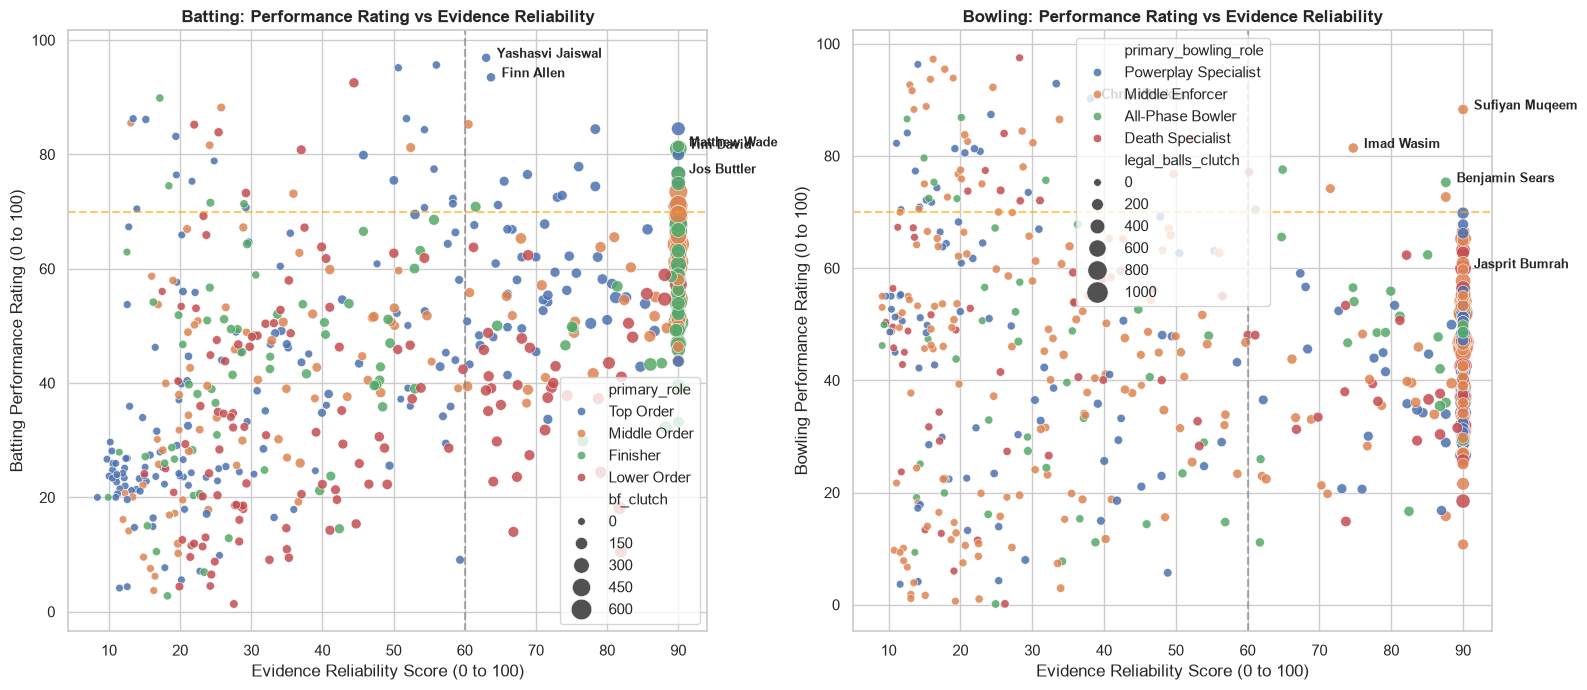

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot 1: Batters Performance vs Evidence
sns.scatterplot(
    data=df_batter_rated[df_batter_rated["bf_overall"] >= 30],
    x="evidence_reliability_score", y="performance_rating",
    hue="primary_role", size="bf_clutch", sizes=(30, 250),
    alpha=0.85, ax=axes[0]
)
axes[0].set_title("Batting: Performance Rating vs Evidence Reliability", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Evidence Reliability Score (0 to 100)")
axes[0].set_ylabel("Batting Performance Rating (0 to 100)")
axes[0].axvline(60.0, color="gray", linestyle="--", alpha=0.6, label="Strong Evidence (60.0)")
axes[0].axhline(70.0, color="orange", linestyle="--", alpha=0.6, label="Elite Rating (70.0)")

# Annotate select players
notable_batters = ["Yashasvi Jaiswal", "Jos Buttler", "Matthew Wade", "Tim David", "Finn Allen"]
for _, r in df_batter_rated[df_batter_rated["striker_name"].isin(notable_batters)].iterrows():
    axes[0].text(r["evidence_reliability_score"] + 1.5, r["performance_rating"], r["striker_name"], fontsize=9, fontweight="bold")

# Plot 2: Bowlers Performance vs Evidence
sns.scatterplot(
    data=df_bowler_rated[df_bowler_rated["legal_balls_overall"] >= 30],
    x="evidence_reliability_score", y="performance_rating",
    hue="primary_bowling_role", size="legal_balls_clutch", sizes=(30, 250),
    alpha=0.85, ax=axes[1]
)
axes[1].set_title("Bowling: Performance Rating vs Evidence Reliability", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Evidence Reliability Score (0 to 100)")
axes[1].set_ylabel("Bowling Performance Rating (0 to 100)")
axes[1].axvline(60.0, color="gray", linestyle="--", alpha=0.6, label="Strong Evidence (60.0)")
axes[1].axhline(70.0, color="orange", linestyle="--", alpha=0.6, label="Elite Rating (70.0)")

notable_bowlers = ["Jasprit Bumrah", "Sufiyan Muqeem", "Chris Woakes", "Imad Wasim", "Benjamin Sears"]
for _, r in df_bowler_rated[df_bowler_rated["bowler_name"].isin(notable_bowlers)].iterrows():
    axes[1].text(r["evidence_reliability_score"] + 1.5, r["performance_rating"], r["bowler_name"], fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


## 10. Robustness & Sensitivity Testing: Stress-Testing the Rankings

A ranking system is scientifically valid only if it does not collapse when reasonable parameter adjustments are made.

We test rank stability across three contrasting weighting philosophies:
1. **Clutch-Heavy Scenario:** Increases clutch scoring and run control weights by +15%.
2. **Baseline-Heavy Scenario:** Increases career baseline and wicket preservation weights by +15%.
3. **Power-Hitting / Wicket-Attacking Bias:** Maximizes boundary hitting and wicket strike rates.


In [10]:
# Run sensitivity analysis
b_sens_summary, b_rank_comp = test_batter_weight_sensitivity(df_batter_rated[df_batter_rated["is_eligible_for_ranking"]])
bw_sens_summary, bw_rank_comp = test_bowler_weight_sensitivity(df_bowler_rated[df_bowler_rated["is_eligible_for_ranking"]])

sens_table = pd.concat([b_sens_summary, bw_sens_summary], ignore_index=True)
print("Ranking Sensitivity and Spearman Rank Correlation Summary:")
display(sens_table)


Ranking Sensitivity and Spearman Rank Correlation Summary:
  Discipline               Scenario  Spearman_Rho  Kendall_Tau  Mean_Rank_Shift  Max_Rank_Shift Top20_Retention
0    Batting           Clutch_Heavy        0.9936       0.9352             7.05              37           18/20
1    Batting         Baseline_Heavy        0.9925       0.9320             7.47              53           18/20
2    Batting     Power_Hitting_Bias        0.9755       0.8719            13.97              70           15/20
3    Bowling           Clutch_Heavy        0.9932       0.9324             7.08              34           18/20
4    Bowling         Baseline_Heavy        0.9805       0.8828            12.37              67           17/20
5    Bowling  Wicket_Attacking_Bias        0.9635       0.8394            16.38              85           14/20


## 11. Verification and Export of Analytical Assets

We verify that all required datasets have been exported cleanly to `data/processed/`:
* `batter_player_ratings.parquet` & `.csv` (888 rows, complete subscores)
* `bowler_player_ratings.parquet` & `.csv` (647 rows, complete subscores)
* `batter_player_rankings.csv` (Main eligible batter ranking)
* `bowler_player_rankings.csv` (Main eligible bowler ranking)
* `player_ranking_sensitivity.csv` (Robustness audit summary)


In [11]:
# Check output assets
export_files = [
    "batter_player_ratings.parquet", "batter_player_ratings.csv",
    "bowler_player_ratings.parquet", "bowler_player_ratings.csv",
    "batter_player_rankings.csv", "bowler_player_rankings.csv",
    "player_ranking_sensitivity.csv"
]

base_dir = "../data/processed" if os.path.exists("../data/processed") else "data/processed"
print("Exported Analytical Assets:")
for f in export_files:
    fpath = os.path.join(base_dir, f)
    if os.path.exists(fpath):
        size_kb = os.path.getsize(fpath) / 1024.0
        print(f"  [OK] {f} ({size_kb:.1f} KB)")
    else:
        print(f"  [MISSING] {f}")

print("\nModule 5: Player Reliability Scores, Evidence-Based Rankings & Player Evaluation Completed Successfully.")


Exported Analytical Assets:
  [OK] batter_player_ratings.parquet (236.1 KB)
  [OK] batter_player_ratings.csv (346.1 KB)
  [OK] bowler_player_ratings.parquet (261.8 KB)
  [OK] bowler_player_ratings.csv (336.3 KB)
  [OK] batter_player_rankings.csv (35.6 KB)
  [OK] bowler_player_rankings.csv (34.4 KB)
  [OK] player_ranking_sensitivity.csv (0.4 KB)

Module 5: Player Reliability Scores, Evidence-Based Rankings & Player Evaluation Completed Successfully.
